# 🚀 Practice Day 38

**📅 Date:** **2026-11-12**  
**📁 Category:** **Phase 3 · NumPy+통계 응용 (Round 3/5)**

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Apply core statistics (mean, standard error, z-score, confidence interval) to compare two production lines, the way a quality engineer would
  (평균·표준오차·z-score·신뢰구간 같은 통계 개념을 두 생산라인 비교에 적용해보기 — 실제 품질관리 분석 방식)
- Find out whether Line B's higher defect rate is a real, statistically meaningful problem or just noise
  (Line B의 높은 불량률이 실제로 통계적으로 유의미한 문제인지, 단순한 노이즈인지 확인하기)

---
# 📂 Dataset

**Dataset Name:** Line A vs Line B — 생산라인 부품 무게 품질관리 데이터 / Production Line QC — Part Weight Measurements

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 400 part-weight measurements from two production lines (A and B), 200 per line. Target weight is 500g, with parts outside ±10g (490-510g) marked defective. Clean — no missing values or duplicates. The focus is on statistically comparing the two lines.
(2개 생산라인(A/B)에서 측정한 부품 무게 400건입니다(라인당 200건). 목표 무게는 500g이며 ±10g(490~510g) 범위를 벗어나면 불량으로 판정합니다. 결측치·중복 없이 깨끗합니다. 두 라인을 통계적으로 비교하는 데 초점을 둡니다.)

## Dataset Preview

In [1]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate part-weight measurements for two production lines ---
n_a, n_b = 200, 200
target = 500.0
tol = 10.0  # spec: target +/- tol is acceptable

weight_a = rng.normal(500.5, 3.5, n_a)
weight_b = rng.normal(503.5, 5.5, n_b)

df = pd.DataFrame({
    'part_id': [f'P{str(i+1).zfill(4)}' for i in range(n_a + n_b)],
    'line': ['A'] * n_a + ['B'] * n_b,
    'weight_g': np.round(np.concatenate([weight_a, weight_b]), 2)
})
df['is_defective'] = ((df['weight_g'] < target - tol) | (df['weight_g'] > target + tol)).astype(int)
df = df.sample(frac=1, random_state=99).reset_index(drop=True)

df.head(10)


,part_id,line,weight_g,is_defective
0,P0062,A,499.33,0
1,P0349,B,494.80,0
2,P0164,A,497.63,0
3,P0008,A,499.39,0
4,P0276,B,505.62,0
5,P0382,B,510.70,1
6,P0209,B,498.67,0
7,P0004,A,503.79,0
8,P0257,B,505.89,0
9,P0168,A,501.85,0


## Dataset Information

In [2]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   part_id       400 non-null    str    
 1   line          400 non-null    str    
 2   weight_g      400 non-null    float64
 3   is_defective  400 non-null    int64  
dtypes: float64(1), int64(1), str(2)
memory usage: 12.6 KB

Shape: (400, 4)


,part_id,line,weight_g,is_defective
count,400,400,400.000000,400.000000
unique,400,2,NaN,NaN
top,P0062,A,NaN,NaN
freq,1,200,NaN,NaN
mean,NaN,NaN,502.001775,0.070000
std,NaN,NaN,4.798846,0.255467
min,NaN,NaN,489.380000,0.000000
25%,NaN,NaN,498.857500,0.000000
50%,NaN,NaN,501.675000,0.000000
75%,NaN,NaN,504.800000,0.000000


---
# ❓ Business Questions

1. **(Analysis)** How much does Line B's average part weight differ from Line A's, and is that difference statistically significant (z-score)?
   (Line B와 Line A의 평균 부품 무게 차이는 얼마이며, 그 차이는 통계적으로 유의한가(z-score)?)
2. **(Analysis)** How much higher is Line B's defect rate compared to Line A, and does the 95% confidence interval for that difference exclude zero?
   (Line B의 불량률은 Line A보다 얼마나 높으며, 그 차이의 95% 신뢰구간은 0을 포함하지 않는가?)
3. **(Analysis)** How does the spread (standard deviation) of part weight compare between the two lines?
   (두 라인의 부품 무게 산포(표준편차)는 어떻게 다른가?)
4. **(Visualization)** Compare the distribution of part weight between the two lines.
   (두 라인의 부품 무게 분포를 비교하면?)
5. **(Visualization)** Compare the defect rate between the two lines.
   (두 라인의 불량률을 비교하면?)

---
# 🔍 Data Cleaning Check


In [3]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
part_id         0
line            0
weight_g        0
is_defective    0
dtype: int64

Duplicate rows: 0

Dtypes
part_id             str
line                str
weight_g        float64
is_defective      int64
dtype: object

Column names
['part_id', 'line', 'weight_g', 'is_defective']

Text columns — unique counts
part_id    400
line         2
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** How much does Line B's average part weight differ from Line A's, and is that difference statistically significant (z-score)? (Line B와 A의 평균 무게 차이는? 통계적으로 유의한가?)

**Result:** Line B averages **503.61** g and Line A **500.39** g, so B is **3.22** g heavier. The z-score is **7.12**.  
(Line B 평균은 **503.61**g, Line A는 **500.39**g이라서 B가 **3.22**g 더 무겁습니다. z-score는 **7.12**)

**Insight:** The z-score is far above **1.96**, so the difference is significant at the 5% level. The standard error is only **0.45** g.  
(z-score가 **1.96**보다 훨씬 커서 5% 수준에서 유의합니다. 표준오차는 **0.45**g에 불과)

In [4]:
# Question 1: mean weight by line, standard error, z-score for the difference

mean_weight_a = np.mean(df[df['line'] == 'A']['weight_g'])
mean_weight_b = np.mean(df[df['line'] == 'B']['weight_g'])
std_weight_a = np.std(df[df['line'] == 'A']['weight_g'])
std_weight_b = np.std(df[df['line'] == 'B']['weight_g'])
n_a = len(df[df['line'] == 'A'])
n_b = len(df[df['line'] == 'B'])
se_weight = np.sqrt((std_weight_a**2 / n_a) + (std_weight_b**2 / n_b))
z_score = (mean_weight_b - mean_weight_a) / se_weight
print(f"Mean weight (Line A): {mean_weight_a:.2f} g")
print(f"Mean weight (Line B): {mean_weight_b:.2f} g")
print(f"Standard deviation (Line A): {std_weight_a:.2f} g")
print(f"Standard deviation (Line B): {std_weight_b:.2f} g")
print(f"Standard error: {se_weight:.2f} g")
print(f"Z-score: {z_score:.2f}")


Mean weight (Line A): 500.39 g
Mean weight (Line B): 503.61 g
Standard deviation (Line A): 3.08 g
Standard deviation (Line B): 5.59 g
Standard error: 0.45 g
Z-score: 7.12


## Question 2

**Question:** How much higher is Line B's defect rate compared to Line A, and does the 95% confidence interval for that difference exclude zero? (Line B 불량률은 A보다 얼마나 높은가? 95% 신뢰구간은 0을 포함하지 않는가?)

**Result:** Line B's defect rate is **13.50%** and Line A's is **0.50%**, so B is **13.00** percentage points higher. The 95% confidence interval for the difference is **[8.16%, 17.84%]**, which excludes zero.  
(Line B 불량률은 **13.50%**, Line A는 **0.50%**라서 B가 **13.00**%p 높습니다. 차이의 95% 신뢰구간은 **[8.16%, 17.84%]**이고 0을 포함하지 않습니다)

**Insight:** Even the lower end, **8.16%**, is far above zero, and the standard error is **2.47%**. Line A's rate of **0.50%** on **200** parts means only **1** defective part.  
(하한 **8.16%**도 0보다 훨씬 높고 표준오차는 **2.47%**입니다. Line A의 **0.50%**는 **200**개 중 불량 **1**개라는 뜻)

In [5]:
# Question 2: defect rate by line, 95% CI for the difference in proportions

defect_rate_a = np.mean(df[df['line'] == 'A']['is_defective'])
defect_rate_b = np.mean(df[df['line'] == 'B']['is_defective'])
n_a = len(df[df['line'] == 'A'])
n_b = len(df[df['line'] == 'B'])
se_defect = np.sqrt((defect_rate_a * (1 - defect_rate_a) / n_a) + (defect_rate_b * (1 - defect_rate_b) / n_b))

# The CI is for the difference (B - A): difference +/- 1.96 * SE
defect_diff = defect_rate_b - defect_rate_a
margin = 1.96 * se_defect
ci_lower = defect_diff - margin
ci_upper = defect_diff + margin

print(f"Defect rate (Line A): {defect_rate_a:.2%}")
print(f"Defect rate (Line B): {defect_rate_b:.2%}")
print(f"Difference (B - A): {defect_diff:.2%}")
print(f"Standard error: {se_defect:.2%}")
print(f"95% Confidence interval: [{ci_lower:.2%}, {ci_upper:.2%}]")
print("Excludes zero:", ci_lower > 0 or ci_upper < 0)


Defect rate (Line A): 0.50%
Defect rate (Line B): 13.50%
Difference (B - A): 13.00%
Standard error: 2.47%
95% Confidence interval: [8.16%, 17.84%]
Excludes zero: True


## Question 3

**Question:** How does the spread (standard deviation) of part weight compare between the two lines? (두 라인의 무게 산포는 어떻게 다른가?)

**Result:** Line B's standard deviation is **5.59** g and Line A's is **3.08** g, a gap of **2.51** g.  
(Line B 표준편차는 **5.59**g, Line A는 **3.08**g으로 **2.51**g 차이입니다)

**Insight:** Line B varies more from part to part, which fits its higher defect rate (**13.50%** vs **0.50%**).  
(Line B는 부품마다 편차가 더 크고, 이는 더 높은 불량률(**13.50%** 대 **0.50%**)과 맞습니다)

In [6]:
# Question 3: standard deviation of weight by line

std_weight_a = np.std(df[df['line'] == 'A']['weight_g'])
std_weight_b = np.std(df[df['line'] == 'B']['weight_g'])
print(f"Standard deviation (Line A): {std_weight_a:.2f} g")
print(f"Standard deviation (Line B): {std_weight_b:.2f} g")

Standard deviation (Line A): 3.08 g
Standard deviation (Line B): 5.59 g


---
# 📈 Visualization

**Chart 1:** Box plot (or histogram) — weight distribution by line (박스플롯 또는 히스토그램: 라인별 무게 분포)

*Interpretation:* Line B's median is about **504** g against about **500** g for Line A, and its box is wider. Line B's whiskers and an outlier reach past both spec limits (**490** g and **510** g), while Line A has one point just above **510** g.  
(Line B 중앙값은 약 **504**g, Line A는 약 **500**g이고 박스도 더 넓습니다. Line B의 수염과 이상치는 규격 한계 **490**g, **510**g을 모두 넘고, Line A는 **510**g을 살짝 넘는 점이 하나 있습니다)

---

**Chart 2:** Bar chart — defect rate by line (막대그래프: 라인별 불량률)

*Interpretation:* Line B's bar is **13.5%** and Line A's is **0.5%**, the **13.0** point gap from Question 2.  
(Line B 막대는 **13.5%**, Line A는 **0.5%**로, Q2의 **13.0**%p 차이와 같습니다)

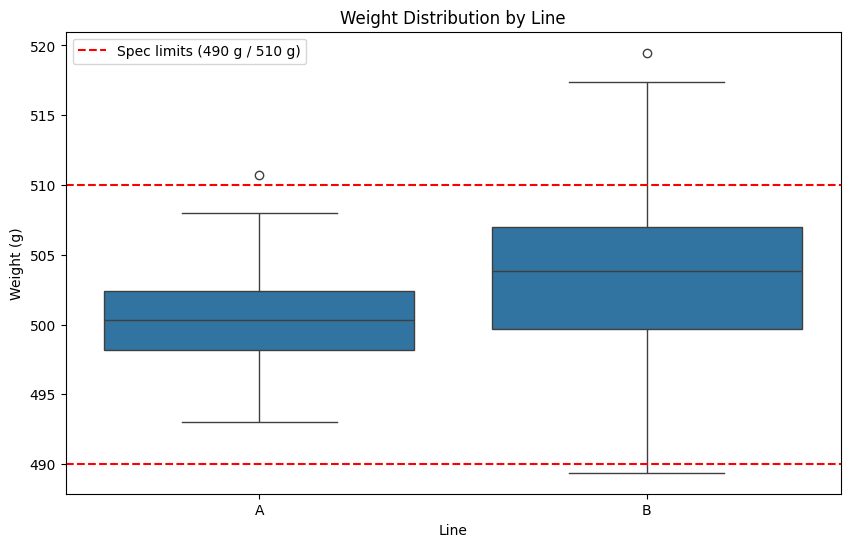

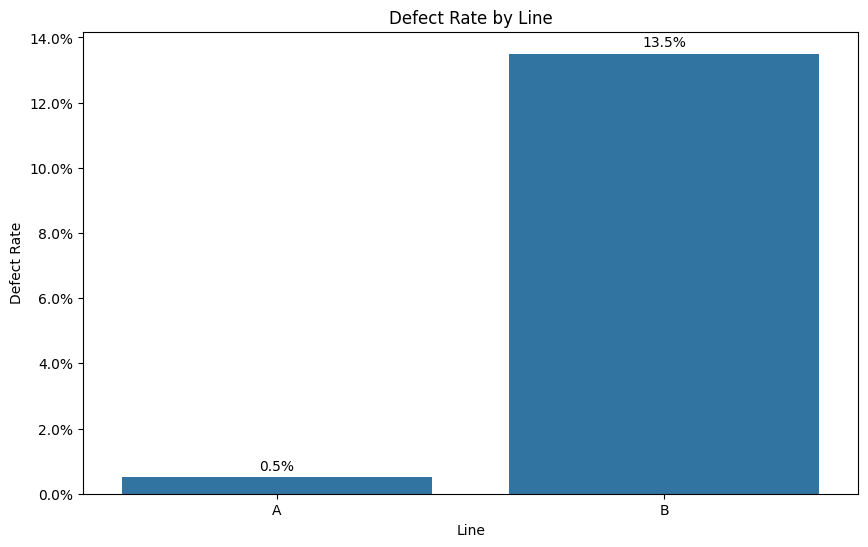

In [7]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

# Chart 1: weight distribution by line (box plot or histogram) - consider marking the 490/510 spec limits
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(x='line', y='weight_g', data=df, ax=ax)
ax.axhline(target - tol, color='red', linestyle='--', label='Spec limits (490 g / 510 g)')
ax.axhline(target + tol, color='red', linestyle='--')
ax.set_title('Weight Distribution by Line')
ax.set_xlabel('Line')
ax.set_ylabel('Weight (g)')
ax.legend()
plt.show()

# Chart 2: defect rate by line (bar)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='line', y='is_defective', data=df, errorbar=None, ax=ax)
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v:.1%}' for v in container.datavalues], padding=3)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title('Defect Rate by Line')
ax.set_xlabel('Line')
ax.set_ylabel('Defect Rate')
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- Line B parts are **3.22** g heavier on average (z-score **7.12**).  
  (Line B 부품이 평균 **3.22**g 더 무거움(z-score **7.12**))
- Line B's defect rate is **13.50%** against **0.50%**, and the 95% interval **[8.16%, 17.84%]** excludes zero.  
  (Line B 불량률은 **13.50%** 대 **0.50%**이고, 95% 신뢰구간 **[8.16%, 17.84%]**은 0을 포함하지 않음)
- Line B's weight spread is larger (**5.59** g vs **3.08** g).  
  (Line B의 무게 산포가 더 큼(**5.59**g 대 **3.08**g))  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Treat Line B's higher defect rate as a real problem, not noise: its interval is **8.16%** to **17.84%** above Line A.  
   (Line B의 높은 불량률은 노이즈가 아니라 실제 문제로 볼 것: Line A보다 **8.16%**~**17.84%**p 높음)
2. Inspect Line B's process for both its heavier mean (**503.61** g vs target **500** g) and its wider spread (**5.59** g).  
   (Line B 공정은 더 무거운 평균(**503.61**g, 목표 **500**g)과 더 큰 산포(**5.59**g)를 함께 점검)
3. Keep checking Line A, since its **0.50%** comes from only **1** defective part in **200**.  
   (Line A의 **0.50%**는 **200**개 중 불량 **1**개뿐이라 계속 확인)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- 
- 
- 

---
# ✅ What I Learned
*Today's biggest lesson*

- The z-score for a difference is (B − A) divided by `sqrt(sd_a²/n_a + sd_b²/n_b)`.  
  (차이의 z-score는 (B − A)를 `sqrt(sd_a²/n_a + sd_b²/n_b)`로 나눈 값)
- The 95% interval for a difference is (B − A) ± 1.96 × SE, and zero outside it means a significant gap.  
  (차이의 95% 구간은 (B − A) ± 1.96 × SE이고, 0이 밖에 있으면 유의한 차이)
- Marking the spec limits on the box plot shows which line goes out of spec.  
  (박스플롯에 규격 한계를 표시하면 어느 라인이 규격을 벗어나는지 보임)  

---
# 🧠 Reflection

**What was difficult?**  
Building the confidence interval for the difference in defect rates.  
(불량률 차이의 신뢰구간 만들기)

**Why?**  
It needs the difference first, then the margin `1.96 * SE` added and subtracted.  
(먼저 차이를 구하고 그 다음 오차범위 `1.96 * SE`를 더하고 빼야 함)

**How did I solve it?**  
I reused the Day 24 steps: difference, margin, lower end, upper end.  
(Day 24 단계를 다시 씀: 차이, 오차범위, 하한, 상한)

**What would I do differently next time?**  
Note how few defective parts a group has before trusting the interval.  
(구간을 믿기 전에 그룹의 불량 개수가 몇 개인지 먼저 확인하기)

---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★★☆☆  
The z-score, the interval, and the spread all point to Line B. Its defect rate is **13.50%** against **0.50%**.  
(z-score, 신뢰구간, 산포 모두 Line B를 가리킴. 불량률은 **13.50%** 대 **0.50%**)  

**Confidence**  
★★★★★★★☆☆☆  

**Difficulty**  
★★★★☆☆☆☆☆☆  

---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 52 — Numpy stats  
  (NumPy로 통계 응용하기)  